# HTS noise and models (compact)

A compact rewrite of the fixed full notebook **`Noise adding to the HTS.ipynb`**, which was retired on
4 Nov 2026 after the check in step 9 passed. It runs the same final workflow, with each step written once:

1. **Labelled survey table** (full notebook's 3rd cell)
2. **Noise on the travel inputs, at three levels** (1st, 2nd and 4th cells)
3. **Labels and mobility-graph features** (16th cell)
4. **Household train/test split** (14th cell)
5. **Model comparison on the development households** (16th cell)
6. **Held-out test scores and feature importance** (14th and 13th cells)
7. **Nested cross-validation** (17th and 18th cells)
8. **Two-stage occupation model** (13th cell)
9. **Check against the full notebook**

All results are written to `output/`. Steps 1–5 and 7 reproduce the full notebook's results exactly
(confirmed in step 9). Steps 6 and 8 run the drafts' extra analyses on the final features.
A full run takes about 4 minutes (kernel: Python 3.12).

In [1]:
from pathlib import Path
import json
import re
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.ensemble import BalancedRandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             cohen_kappa_score, confusion_matrix, f1_score, make_scorer, matthews_corrcoef)
from sklearn.model_selection import GroupShuffleSplit, RandomizedSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "axes.axisbelow": True, "font.size": 9})

WORKBOOK = Path("HTS_Bengaluru_Synthetic_Responses_1200.xlsx")
OUT = Path("output")
OUT.mkdir(exist_ok=True)
SEED = 42
NOISE_LEVELS = {"low": 0.03, "medium": 0.05, "high": 0.10}
MODEL_INPUT = "medium"                # noise level the models are trained and tested on
FEATURE_PROFILE = "survey_enriched"   # "mobility_only" drops purpose and cost (telecom / GPS-style inputs)

## 1. Labelled survey table

One row per trip, with labels taken from the workbook's own Codebook sheet.

In [2]:
sheets = pd.read_excel(WORKBOOK, sheet_name=["A_Households", "B_Person_Roster", "E_Trips_Full", "Codebook"])
codebook = sheets["Codebook"]


def codebook_labels(variable):
    rows = codebook[codebook["Variable"] == variable]
    return dict(zip(rows["Code"].astype(int), rows["Meaning"]))


BAND_TO_INR = {"Below ₹15,000": 12000, "₹15,000 to ₹30,000": 22500, "₹30,000 to ₹60,000": 45000,
               "₹60,000 to ₹1,00,000": 80000, "Above ₹1,00,000": 150000}  # "Refused" stays missing

trips = sheets["E_Trips_Full"].copy()
trips["mode"] = trips["E8_Primary_mode"].map(codebook_labels("Mode (C4,C5,D3,E8,E9)"))
trips["trip_purpose"] = trips["E4_Purpose"].map(codebook_labels("Purpose (E4)"))
trips["trip_distance_km"] = pd.to_numeric(trips["E7_Distance_km"], errors="coerce")
trips["trip_duration_min"] = pd.to_numeric(trips["E6_Travel_time_min"], errors="coerce")
trips["departure_time_hhmm"] = trips["E5_Departure"].astype(str)
trips["travel_cost_inr"] = pd.to_numeric(trips["E10_Cost_INR"], errors="coerce")
persons = sheets["B_Person_Roster"]
households = sheets["A_Households"]
persons = persons.assign(occupation=persons["B4_Activity"].map(codebook_labels("B4 Activity")))
households = households.assign(household_monthly_income_inr=households["A4_Expenditure_band"].map(BAND_TO_INR))

survey = (trips.merge(persons[["HH_ID", "Person_ID", "occupation"]], on=["HH_ID", "Person_ID"], how="left")
               .merge(households[["HH_ID", "household_monthly_income_inr"]], on="HH_ID", how="left"))
survey.to_csv(OUT / "bengaluru_synthetic_person_trip_survey.csv", index=False)
print(f"{len(survey)} trips, {survey.groupby(['HH_ID', 'Person_ID']).ngroups} travellers, "
      f"{survey['HH_ID'].nunique()} households")

8687 trips, 3383 travellers, 1165 households


## 2. Noise on the travel inputs

Survey reporting errors are applied to **inputs only**. The labels (income, occupation, mode) stay clean,
because the models are scored against them.
- **Forgotten trips:** a share of short (under 3 km) discretionary trips is dropped.
- **Departure-time recall error.**
- **Distance and duration estimation error.**

In [3]:
def hhmm_to_minutes(value):
    try:
        hours, minutes = str(value).split(":")
        return int(hours) * 60 + int(minutes)
    except ValueError:
        return np.nan


def minutes_to_hhmm(minutes):
    minutes = int(minutes) % (24 * 60)
    return f"{minutes // 60:02d}:{minutes % 60:02d}"


SHORT_DISCRETIONARY = ["shopping", "other", "social", "recreation", "leisure"]


def add_hts_noise(df, noise_level, random_state=SEED):
    rng = np.random.default_rng(random_state)
    noisy = df.copy()
    candidates = noisy[(noisy["trip_distance_km"] < 3)
                       & noisy["trip_purpose"].astype(str).str.lower().isin(SHORT_DISCRETIONARY)].index
    remove_count = int(len(candidates) * noise_level * 1.5)
    if remove_count > 0:
        noisy = noisy.drop(index=rng.choice(candidates, size=remove_count, replace=False)).reset_index(drop=True)
    n = len(noisy)
    departure = noisy["departure_time_hhmm"].apply(hhmm_to_minutes) + rng.normal(0, noise_level * 150, n)
    noisy["departure_time_hhmm"] = departure.clip(0, 1439).apply(minutes_to_hhmm)
    noisy["trip_distance_km"] = (noisy["trip_distance_km"] * rng.normal(1.0, noise_level * 1.5, n)).clip(lower=0.1)
    noisy["trip_duration_min"] = (noisy["trip_duration_min"] * rng.normal(1.0, noise_level * 2.0, n)).clip(lower=1)
    return noisy


clean = pd.read_csv(OUT / "bengaluru_synthetic_person_trip_survey.csv")
noise_summary = []
for level_name, level in NOISE_LEVELS.items():
    path = OUT / f"bengaluru_hts_noisy_{level_name}.csv"
    noisy = add_hts_noise(clean, level)
    noisy.to_csv(path, index=False)
    noise_summary.append({"scenario": level_name, "noise_level": level, "original_rows": len(clean),
                          "noisy_rows": len(noisy), "output_file": str(path)})
noise_summary = pd.DataFrame(noise_summary)
noise_summary.to_csv(OUT / "hts_noise_summary.csv", index=False)
noise_summary

,scenario,noise_level,original_rows,noisy_rows,output_file
0,low,0.03,8687,8662,output/bengaluru_hts_noisy_low.csv
1,medium,0.05,8687,8645,output/bengaluru_hts_noisy_medium.csv
2,high,0.10,8687,8603,output/bengaluru_hts_noisy_high.csv


## 3. Labels and mobility-graph features

One row per traveller (occupation, primary mode) and one per household (income).

In [4]:
def normalize(value):
    return "" if pd.isna(value) else re.sub(r"[\s_-]+", " ", str(value).strip().lower())


def occupation_class(value):
    v = normalize(value)
    if v in {"", "unknown", "missing", "none", "nan"}:
        return np.nan
    for label, words in [("non_employed", ["unemploy", "non employ", "not employ", "retir"]),
                         ("student_child", ["student", "child", "pupil"]),
                         ("homemaker", ["homemaker", "home maker", "housewife", "househusband"]),
                         ("employed", ["employ", "salar", "business", "worker", "professional"])]:
        if any(w in v for w in words):
            return label
    return "other"


def mode_class(value):
    v = normalize(value)
    if any(w in v for w in ["ride hail", "rickshaw"]):
        return "paid_private_vehicle"
    if v in {"", "unknown", "missing", "none", "nan"}:
        return np.nan
    for label, words in [("rail_based_public_transport", ["metro", "rail", "train"]),
                         ("paid_private_vehicle", ["auto", "cab", "taxi", "uber", "ola"]),
                         ("bus", ["bus", "bmtc"]),
                         ("two_wheeler", ["two wheeler", "motorcycle", "motorbike", "scooter"]),
                         ("active_transport", ["walk", "bicycle", "cycling", "cycle"]),
                         ("private_car", ["car"])]:
        if any(w in v for w in words):
            return label
    return "other"


def income_class(value):
    if pd.isna(value):
        return np.nan
    return "low_or_lower_middle" if value < 50000 else "middle" if value < 100000 else "high"


def parse_time(value):
    m = re.search(r"(\d{1,2}):(\d{2})", str(value))
    if not m or not (0 <= int(m[1]) < 24 and 0 <= int(m[2]) < 60):
        return np.nan
    return float(int(m[1]) * 60 + int(m[2]))


def single_label(series):
    values = series.dropna().unique()
    return values[0] if len(values) == 1 else np.nan


def entropy(series):
    p = series.dropna().value_counts(normalize=True)
    return float(-(p * np.log(p)).sum()) if len(p) else np.nan


def share(mask, valid):
    return float(mask[valid].mean()) if valid.any() else np.nan


def summary(record, name, values, n):
    valid = values.dropna().astype(float)
    for stat in ["mean", "median", "min", "max", "std"]:
        record[f"{name}_{stat}"] = float(getattr(valid, stat)()) if len(valid) else np.nan
    record[f"{name}_missing_share"] = 1 - len(valid) / n


def mobility_features(t):
    """Mobility-graph, distance, duration, speed and timing features for one traveller's trips."""
    n = len(t)
    f = {"trip_count": n}
    valid = t.dropna(subset=["origin", "destination"])
    nodes = pd.concat([valid["origin"], valid["destination"]]).unique()
    edges = valid.groupby(["origin", "destination"]).size()
    directed = set(valid.loc[valid["origin"] != valid["destination"], ["origin", "destination"]]
                   .itertuples(index=False, name=None))
    f["node_count"], f["edge_count"], f["valid_edge_share"] = len(nodes), len(edges), len(valid) / n
    f["density"] = len(directed) / (len(nodes) * (len(nodes) - 1)) if len(nodes) > 1 else 0.0
    f["reciprocity"] = sum((b, a) in directed for a, b in directed) / len(directed) if directed else 0.0
    f["dominant_edge_share"] = float(edges.max() / edges.sum()) if len(edges) else np.nan
    f["destination_entropy"], f["origin_entropy"] = entropy(t["destination"]), entropy(t["origin"])

    dist, dur, time = t["distance"], t["duration"], t["departure_min"]
    summary(f, "distance", dist, n)
    summary(f, "duration", dur, n)
    ok = dist.notna() & dur.notna() & dur.gt(0)
    summary(f, "speed", dist[ok] / (dur[ok] / 60), n)
    for name, mask in {"short_share": dist.lt(3), "medium_share": dist.ge(3) & dist.lt(10),
                       "long_share": dist.ge(10)}.items():
        f[name] = share(mask, dist.notna())
    for name, start, end in [("morning_share", 360, 720), ("afternoon_share", 720, 1020),
                             ("evening_share", 1020, 1200), ("morning_peak_share", 480, 600),
                             ("evening_peak_share", 1020, 1140)]:
        f[name] = share(time.ge(start) & time.lt(end), time.notna())
    angles = 2 * np.pi * time.dropna() / 1440
    f["time_sin_mean"] = float(np.sin(angles).mean()) if len(angles) else np.nan
    f["time_cos_mean"] = float(np.cos(angles).mean()) if len(angles) else np.nan

    if FEATURE_PROFILE == "survey_enriched":          # survey-only inputs: telecom / GPS data lack these
        cost = t["cost"]
        summary(f, "cost", cost, n)
        ok = cost.notna() & dist.notna() & dist.gt(0)
        f["cost_per_km"] = float(cost[ok].sum() / dist[ok].sum()) if ok.any() else np.nan
        purpose = t["purpose"].map(normalize)
        known = purpose.ne("")
        f["purpose_entropy"] = entropy(purpose.where(known))
        for name, pattern in {"work": r"\bwork\b|office|business",
                              "education": r"education|school|college|university", "shopping": r"shop"}.items():
            f[f"purpose_{name}_share"] = share(purpose.str.contains(pattern, regex=True), known)
    return f


def standardize(noisy):
    """Rename the noisy survey file's columns and derive the label columns."""
    d = noisy.rename(columns={"HH_ID": "household_id", "Person_ID": "person_id", "E2_Origin_PIN": "origin",
                              "E3_Dest_PIN": "destination", "trip_distance_km": "distance",
                              "trip_duration_min": "duration", "travel_cost_inr": "cost",
                              "departure_time_hhmm": "departure", "trip_purpose": "purpose",
                              "mode": "raw_mode", "occupation": "raw_occupation",
                              "household_monthly_income_inr": "income"})
    for col in ["household_id", "person_id", "origin", "destination"]:
        d[col] = d[col].astype(str)
    d["traveler_id"] = d["household_id"].str.len().astype(str) + ":" + d["household_id"] + "|" + d["person_id"]
    d["departure_min"] = d["departure"].map(parse_time)
    d["occupation_label"] = d["raw_occupation"].map(occupation_class)
    d["mode_label"] = d["raw_mode"].map(mode_class)
    d["income_category"] = d["income"].map(income_class)
    return d


def build_tables(d):
    """One row per traveller (occupation, primary mode) and per household (income)."""
    occupation = d.groupby("traveler_id")["occupation_label"].agg(single_label)
    income = d.groupby("household_id")["income_category"].agg(single_label)
    rows = []
    for traveler, t in d.groupby("traveler_id", sort=False):
        r = mobility_features(t)
        counts = t["mode_label"].dropna().value_counts()
        winners = counts[counts == counts.max()].index if len(counts) else []
        r.update(record_id=traveler, household_id=t["household_id"].iloc[0],
                 label_occupation=occupation.get(traveler, np.nan),
                 label_primary_mode=winners[0] if len(winners) == 1 else np.nan)  # ties left unlabelled
        rows.append(r)
    people = pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan)
    person_features = [c for c in people.columns
                       if c not in {"record_id", "household_id", "label_occupation", "label_primary_mode"}]
    hh = people.groupby("household_id")[person_features].agg(["mean", "max", "std"])
    hh.columns = [f"person_{feat}_{agg}" for feat, agg in hh.columns]
    hh["observed_traveler_count"] = people.groupby("household_id").size()
    hh["observed_trip_count"] = d.groupby("household_id").size()
    hh = hh.reset_index()
    hh["record_id"] = hh["household_id"]
    hh["label_income_class"] = hh["household_id"].map(income)
    return people, hh.replace([np.inf, -np.inf], np.nan)


noisy = pd.read_csv(OUT / f"bengaluru_hts_noisy_{MODEL_INPUT}.csv")
trip_table = standardize(noisy)
people, households = build_tables(trip_table)
people.to_csv(OUT / "person_level_table.csv", index=False)
households.to_csv(OUT / "household_level_table.csv", index=False)
for raw, label in [("raw_occupation", "occupation_label"), ("raw_mode", "mode_label")]:
    (trip_table.groupby([raw, label], dropna=False).size().rename("trip_rows").reset_index()
     .to_csv(OUT / f"{raw.removeprefix('raw_')}_mapping.csv", index=False))

conflicts = {"travellers with conflicting occupations": trip_table.groupby("traveler_id")["occupation_label"].nunique().gt(1).sum(),
             "households with conflicting income classes": trip_table.groupby("household_id")["income_category"].nunique().gt(1).sum()}
print(f"people {people.shape}, households {households.shape}", conflicts)
print(people["label_occupation"].value_counts().to_dict())

people (3383, 52), households (1165, 149) {'travellers with conflicting occupations': np.int64(0), 'households with conflicting income classes': np.int64(0)}
{'employed': 1687, 'student_child': 755, 'homemaker': 657, 'non_employed': 202, 'other': 82}


## 4. Household train/test split

Every household sits on one side only, and every class of every target appears on both sides.

In [5]:
def household_holdout(people, d, test_size=0.20):
    """First of 100 household-grouped shuffles in which every class of every target is in both parts."""
    traveler_income = d.groupby("traveler_id")["income_category"].agg(single_label)
    table = people.assign(label_income_class=people["record_id"].map(traveler_income))
    targets = ["label_occupation", "label_income_class", "label_primary_mode"]
    for train_idx, test_idx in GroupShuffleSplit(100, test_size=test_size, random_state=SEED).split(
            table, groups=table["household_id"]):
        train, test = table.iloc[train_idx], table.iloc[test_idx]
        if all(set(train[t].dropna()) == set(table[t].dropna()) == set(test[t].dropna())
               and train.dropna(subset=[t]).groupby(t)["household_id"].nunique().min() >= 2 for t in targets):
            split = pd.Series("development", index=table["household_id"])
            split.iloc[test_idx] = "test"
            return split[~split.index.duplicated()]
    raise ValueError("no household split with full class coverage")


split = household_holdout(people, trip_table)
split.rename("split").to_csv(OUT / "household_split.csv", index_label="household_id")
split.value_counts()

development    932
test           233
Name: count, dtype: int64

## 5. Model comparison on the development households

Each candidate is tuned by randomized search over 5 household-grouped folds and ranked by **macro-F1**,
the average F1 over classes, so rare classes count as much as common ones.

occupation_person: selected extra_trees


primary_mode_person: selected extra_trees


income_household: selected logistic_regression


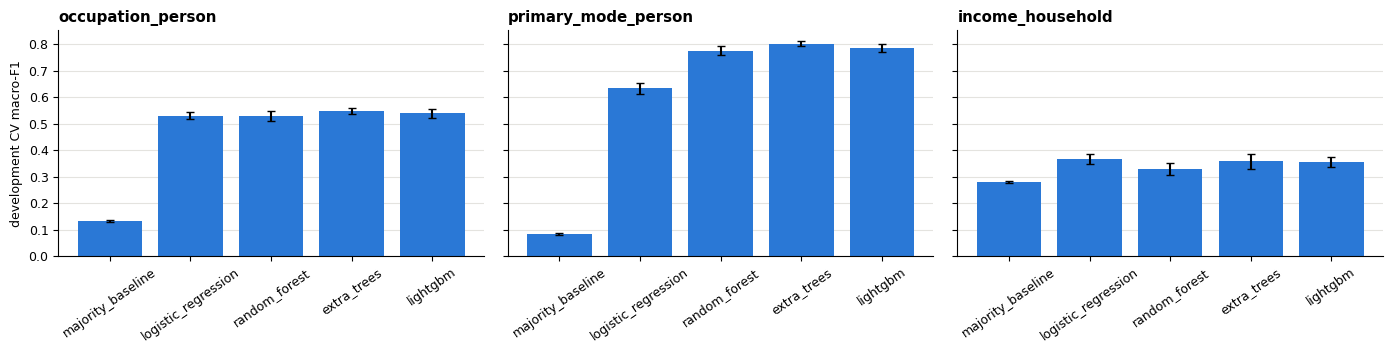

task,income_household,occupation_person,primary_mode_person
model,,,
extra_trees,0.3586,0.5495,0.8026
lightgbm,0.3546,0.5398,0.7863
logistic_regression,0.3669,0.5294,0.6341
majority_baseline,0.2795,0.1339,0.0832
random_forest,0.3280,0.5278,0.7757


In [6]:
LABELS = ["label_occupation", "label_primary_mode", "label_income_class"]
TASKS = {"occupation_person": (people, "label_occupation"),
         "primary_mode_person": (people, "label_primary_mode"),
         "income_household": (households, "label_income_class")}


def make_pipeline(model):
    return Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                     ("scaler", StandardScaler()), ("model", model)])


def to_float(frame):
    """Features as floats; missing values (<NA> or NaN) become NaN, which the imputer fills."""
    return frame.astype(object).where(frame.notna(), np.nan).astype(float)


def class_complete_folds(y, groups, n_folds, seed, attempts):
    """Household-grouped stratified folds in which every class is in every training and validation part."""
    y, groups = np.asarray(y), np.asarray(groups)
    most = min(n_folds, int(pd.Series(groups).groupby(y).nunique().min()))
    for k in range(most, 1, -1):
        for attempt in range(attempts):
            folds = list(StratifiedGroupKFold(k, shuffle=True, random_state=seed + attempt)
                         .split(np.zeros((len(y), 1)), y, groups))
            if all(set(y[a]) == set(y) == set(y[b]) for a, b in folds):
                return folds
    raise ValueError("not enough households for class-complete folds")


def task_data(task):
    table, target = TASKS[task]
    table = table.assign(split=table["household_id"].map(split))
    return (table[table["split"] == "development"].dropna(subset=[target]),
            table[table["split"] == "test"].dropna(subset=[target]), target)


TREE_GRID = {"model__n_estimators": [300, 600], "model__max_depth": [8, 16, None],
             "model__min_samples_leaf": [1, 2, 5, 10], "model__max_features": ["sqrt", 0.7]}
SELECTION_CANDIDATES = {
    "majority_baseline": (DummyClassifier(strategy="most_frequent"), {}),
    "logistic_regression": (LogisticRegression(max_iter=5000, random_state=SEED),
                            {"model__C": [0.01, 0.1, 1.0, 10.0], "model__class_weight": [None, "balanced"]}),
    "random_forest": (RandomForestClassifier(n_jobs=1, random_state=SEED),
                      {**TREE_GRID, "model__class_weight": [None, "balanced", "balanced_subsample"]}),
    "extra_trees": (ExtraTreesClassifier(n_jobs=1, random_state=SEED),
                    {**TREE_GRID, "model__class_weight": [None, "balanced"]}),
    "lightgbm": (LGBMClassifier(n_jobs=1, random_state=SEED, verbosity=-1, subsample_freq=1),
                 {"model__n_estimators": [150, 300, 500], "model__learning_rate": [0.03, 0.07],
                  "model__num_leaves": [7, 15, 31], "model__min_child_samples": [10, 25, 50],
                  "model__class_weight": [None, "balanced"], "model__subsample": [0.8, 1.0],
                  "model__colsample_bytree": [0.8, 1.0]}),
}

comparison, selected = [], {}
for task in TASKS:
    dev, _, target = task_data(task)
    features = [c for c in dev.columns
                if c not in {"record_id", "household_id", "split", *LABELS} and dev[c].notna().any()]
    X, encoder = to_float(dev[features]), LabelEncoder()
    y = encoder.fit_transform(dev[target])
    labels = np.arange(len(encoder.classes_))
    folds = class_complete_folds(y, dev["household_id"], 5, SEED, attempts=10)
    scoring = {"macro_f1": make_scorer(f1_score, labels=labels, average="macro", zero_division=0),
               "accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"}
    rows, fitted = [], {}
    for name, (model, grid) in SELECTION_CANDIDATES.items():
        search = RandomizedSearchCV(make_pipeline(model), grid, n_iter=10 if grid else 1, scoring=scoring,
                                    refit="macro_f1", cv=folds, n_jobs=-1, random_state=SEED,
                                    error_score="raise").fit(X, y)
        cv, i = search.cv_results_, search.best_index_
        rows.append({"task": task, "model": name, "development_n": len(dev),
                     "development_households": dev["household_id"].nunique(),
                     "cv_macro_f1": cv["mean_test_macro_f1"][i], "cv_macro_f1_std": cv["std_test_macro_f1"][i],
                     "cv_accuracy": cv["mean_test_accuracy"][i],
                     "cv_balanced_accuracy": cv["mean_test_balanced_accuracy"][i],
                     "parameters": json.dumps(search.best_params_, default=str)})
        fitted[name] = search.best_estimator_
    winner = pd.DataFrame(rows).sort_values("cv_macro_f1", ascending=False).iloc[0]["model"]
    selected[task] = {"pipeline": fitted[winner], "label_encoder": encoder, "features": features,
                      "target": target, "task": task, "model": winner, "feature_profile": FEATURE_PROFILE}
    joblib.dump(selected[task], OUT / f"{task}_selected_model.joblib")
    comparison += rows
    print(f"{task}: selected {winner}")

comparison = pd.DataFrame(comparison)
comparison.to_csv(OUT / "all_model_cv_comparison.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, (task, rows) in zip(axes, comparison.groupby("task", sort=False)):
    ax.bar(rows["model"], rows["cv_macro_f1"], yerr=rows["cv_macro_f1_std"], capsize=3, color="#2a78d6")
    ax.set_title(task, loc="left", fontweight="bold")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("development CV macro-F1")
fig.tight_layout()
fig.savefig(OUT / "cv_comparison.png", dpi=200)
plt.show()
comparison.pivot(index="model", columns="task", values="cv_macro_f1").round(4)

## 6. Held-out test scores and feature importance

The selected models are scored **once** on the test households, next to the majority-class baseline.
*Permutation importance* measures how much test macro-F1 drops when one feature is shuffled.

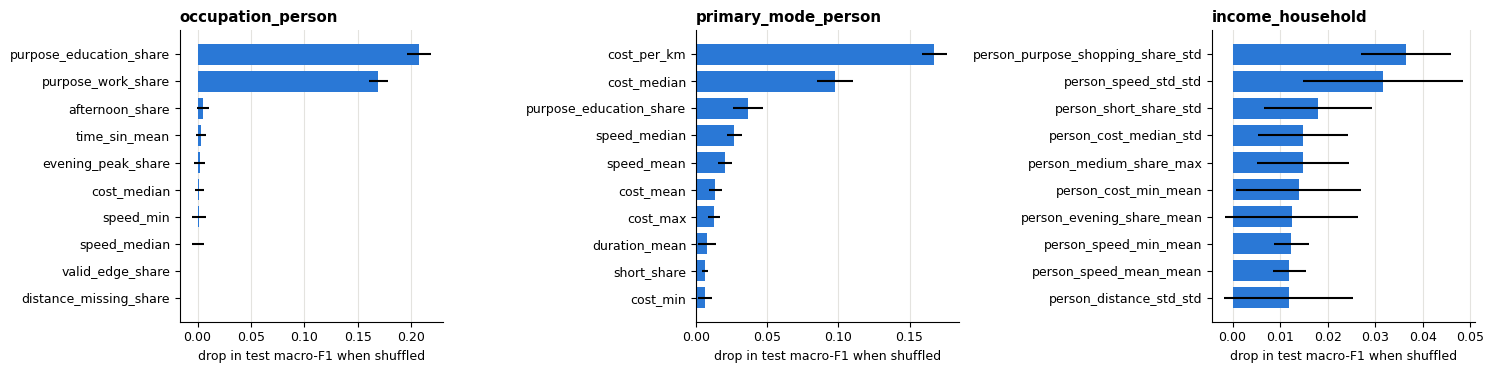

,task,model,test_n,test_accuracy,baseline_accuracy,test_macro_f1,baseline_macro_f1,test_balanced_accuracy,test_mcc,ordinal_mae,weighted_kappa
0,occupation_person,extra_trees,694,0.7219,0.4813,0.5503,0.1300,0.5666,0.6238,NaN,NaN
1,primary_mode_person,extra_trees,642,0.8692,0.3193,0.8074,0.0807,0.7927,0.8326,NaN,NaN
2,income_household,logistic_regression,227,0.4626,0.7225,0.3580,0.2796,0.3898,0.0719,0.7621,0.0475


In [7]:
INCOME_ORDER = {"low_or_lower_middle": 0, "middle": 1, "high": 2}
test_results, importance = [], []
for task, s in selected.items():
    dev, test, target = task_data(task)
    enc = s["label_encoder"]
    if not set(test[target]) <= set(enc.classes_):
        print(f"{task}: test set has a class unseen in development; skipped")
        continue
    X_test, y_test = to_float(test[s["features"]]), enc.transform(test[target])
    labels = np.arange(len(enc.classes_))
    pred = s["pipeline"].predict(X_test).astype(int)
    baseline = np.full(len(y_test), np.bincount(enc.transform(dev[target])).argmax())
    row = {"task": task, "model": s["model"], "test_n": len(y_test),
           "test_accuracy": accuracy_score(y_test, pred), "baseline_accuracy": accuracy_score(y_test, baseline),
           "test_macro_f1": f1_score(y_test, pred, labels=labels, average="macro", zero_division=0),
           "baseline_macro_f1": f1_score(y_test, baseline, labels=labels, average="macro", zero_division=0),
           "test_balanced_accuracy": balanced_accuracy_score(y_test, pred), "test_mcc": matthews_corrcoef(y_test, pred)}
    if task == "income_household":
        actual, predicted = (np.array([INCOME_ORDER[v] for v in enc.inverse_transform(a)]) for a in (y_test, pred))
        row["ordinal_mae"] = float(np.abs(actual - predicted).mean())
        row["weighted_kappa"] = cohen_kappa_score(actual, predicted, labels=[0, 1, 2], weights="quadratic")
    test_results.append(row)
    pd.DataFrame(classification_report(y_test, pred, labels=labels, target_names=enc.classes_,
                                       zero_division=0, output_dict=True)).T.to_csv(OUT / f"{task}_test_report.csv")
    pd.DataFrame(confusion_matrix(y_test, pred, labels=labels), index=enc.classes_,
                 columns=enc.classes_).to_csv(OUT / f"{task}_test_confusion_matrix.csv")
    imp = permutation_importance(s["pipeline"], X_test, y_test, n_repeats=10, random_state=SEED, n_jobs=-1,
                                 scoring=make_scorer(f1_score, labels=labels, average="macro", zero_division=0))
    importance += [{"task": task, "feature": f, "importance": m, "std": sd}
                   for f, m, sd in zip(s["features"], imp.importances_mean, imp.importances_std)]

test_results = pd.DataFrame(test_results)
test_results.to_csv(OUT / "test_results.csv", index=False)
importance = pd.DataFrame(importance)
importance.to_csv(OUT / "feature_importance.csv", index=False)

fig, axes = plt.subplots(1, len(test_results), figsize=(15, 3.8))
for ax, (task, rows) in zip(np.atleast_1d(axes), importance.groupby("task", sort=False)):
    top = rows.nlargest(10, "importance").iloc[::-1]
    ax.barh(top["feature"], top["importance"], xerr=top["std"], color="#2a78d6")
    ax.set_title(task, loc="left", fontweight="bold")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("drop in test macro-F1 when shuffled")
fig.tight_layout()
fig.savefig(OUT / "feature_importance.png", dpi=200)
plt.show()
test_results.round(4)

## 7. Nested cross-validation

The model is chosen *inside* each of 3 outer folds, so the outer scores are not flattered by model selection.
Development households only; the test households stay unused.

occupation_person fold 1: lightgbm, macro-F1 0.5104


occupation_person fold 2: lightgbm, macro-F1 0.5213


occupation_person fold 3: lightgbm, macro-F1 0.5321


primary_mode_person fold 1: extra_trees, macro-F1 0.7810


primary_mode_person fold 2: lightgbm, macro-F1 0.7765


primary_mode_person fold 3: random_forest, macro-F1 0.7768


income_household fold 1: extra_trees, macro-F1 0.3166


income_household fold 2: rbf_svm, macro-F1 0.3761


income_household fold 3: balanced_random_forest, macro-F1 0.3519


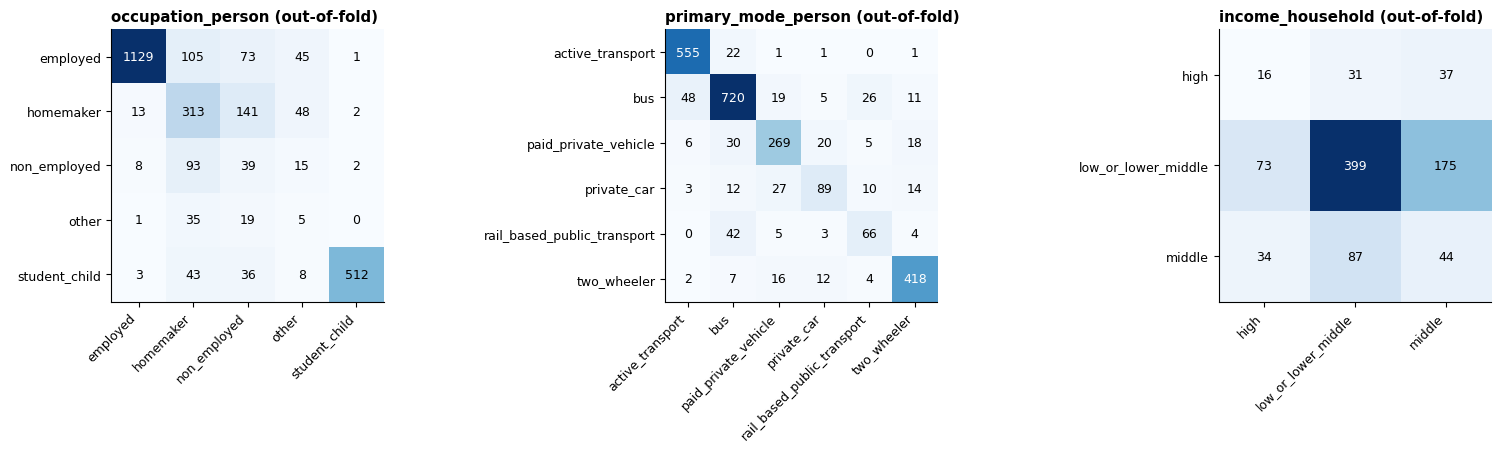

,task,n_classes,accuracy_mean,macro_f1_mean,macro_f1_std,mcc_mean,baseline_macro_f1_mean,macro_f1_gain_over_baseline
0,occupation_person,5,0.7433,0.5213,0.0109,0.6353,0.1339,0.3874
1,primary_mode_person,6,0.8500,0.7781,0.0025,0.8061,0.0832,0.6949
2,income_household,3,0.5123,0.3482,0.0299,0.0605,0.2795,0.0687


In [8]:
NESTED_GRID = {"model__n_estimators": [250, 450], "model__max_depth": [6, 12, None],
               "model__min_samples_leaf": [1, 3, 8, 15], "model__max_features": ["sqrt", 0.7]}
NESTED_CANDIDATES = {
    "majority_baseline": (DummyClassifier(strategy="most_frequent"), {}),
    "random_forest": (RandomForestClassifier(random_state=SEED, n_jobs=1),
                      {**NESTED_GRID, "model__class_weight": [None, "balanced", "balanced_subsample"]}),
    "extra_trees": (ExtraTreesClassifier(random_state=SEED, n_jobs=1),
                    {**NESTED_GRID, "model__class_weight": [None, "balanced"]}),
    "rbf_svm": (SVC(kernel="rbf", cache_size=512),
                {"model__C": [0.1, 1.0, 10.0, 50.0], "model__gamma": ["scale", 0.001, 0.01, 0.1],
                 "model__class_weight": [None, "balanced"]}),
    "balanced_random_forest": (BalancedRandomForestClassifier(random_state=SEED, n_jobs=1, sampling_strategy="all",
                                                              replacement=True, bootstrap=False),
                               {"model__n_estimators": [250, 450], "model__max_depth": [4, 8, 16, None],
                                "model__min_samples_leaf": [1, 3, 8], "model__max_features": ["sqrt", 0.7]}),
    "lightgbm": (LGBMClassifier(random_state=SEED, n_jobs=1, verbosity=-1, subsample_freq=1),
                 {"model__n_estimators": [150, 300], "model__learning_rate": [0.03, 0.07],
                  "model__num_leaves": [7, 15, 31], "model__min_child_samples": [15, 30, 60],
                  "model__reg_lambda": [0.0, 1.0, 5.0], "model__class_weight": [None, "balanced"],
                  "model__subsample": [0.8, 1.0], "model__colsample_bytree": [0.8, 1.0]}),
}
LEAKAGE_KEYWORDS = {"occupation_person": ["occupation"], "primary_mode_person": ["primary_mode"],
                    "income_household": ["income"]}


def macro_f1(y_true, y_pred, labels):
    return f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)


def scores(y_true, y_pred, labels):
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": macro_f1(y_true, y_pred, labels),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred), "mcc": matthews_corrcoef(y_true, y_pred)}


def search_best(X, y, folds, labels):
    """Tune every candidate on the folds; return the best non-baseline one (the baseline is for reference)."""
    rows, fitted = [], {}
    for name, (model, grid) in NESTED_CANDIDATES.items():
        if grid:
            search = RandomizedSearchCV(make_pipeline(model), grid, n_iter=5, cv=folds, refit=True, n_jobs=-1,
                                        random_state=SEED, error_score="raise",
                                        scoring=make_scorer(f1_score, labels=labels, average="macro",
                                                            zero_division=0)).fit(X, y)
            score, fitted[name], params = search.best_score_, search.best_estimator_, search.best_params_
        else:
            score = np.mean([macro_f1(y[b], clone(make_pipeline(model)).fit(X.iloc[a], y[a]).predict(X.iloc[b]), labels)
                             for a, b in folds])
            fitted[name], params = clone(make_pipeline(model)).fit(X, y), {}
        rows.append({"model": name, "inner_cv_macro_f1": float(score), "parameters": json.dumps(params, default=str)})
    best = (pd.DataFrame(rows).query("model != 'majority_baseline'")
            .sort_values("inner_cv_macro_f1", ascending=False, kind="stable").iloc[0]["model"])
    return best, fitted[best], rows


outer_results, inner_results, nested_summary = [], [], []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (task, (table, target)) in zip(axes, TASKS.items()):
    dev = (table.assign(split=table["household_id"].map(split)).query("split == 'development'")
           .dropna(subset=[target]).reset_index(drop=True))
    rare = dev.groupby(target)["household_id"].nunique().loc[lambda s: s < 3].index
    if len(rare):
        print(f"{task}: dropped classes with fewer than 3 households: {list(rare)}")
        dev = dev[~dev[target].isin(rare)].reset_index(drop=True)
    features = [c for c in dev.columns if c not in {"record_id", "household_id", "split", *LABELS}
                and not c.startswith("audit_") and not any(k in c.lower() for k in LEAKAGE_KEYWORDS[task])]
    X, encoder = to_float(dev[features].replace([np.inf, -np.inf], np.nan)), LabelEncoder()
    y, groups = encoder.fit_transform(dev[target]), dev["household_id"].to_numpy()
    labels = np.arange(len(encoder.classes_))

    oof, task_rows = np.full(len(y), -1), []
    for k, (tr, va) in enumerate(class_complete_folds(y, groups, 3, SEED, attempts=25), start=1):
        inner = class_complete_folds(y[tr], groups[tr], 3, SEED + 100 * k, attempts=25)
        winner, model, rows = search_best(X.iloc[tr], y[tr], inner, labels)
        oof[va] = model.predict(X.iloc[va]).astype(int)
        majority = np.full(len(va), np.bincount(y[tr], minlength=len(labels)).argmax())
        task_rows.append({"task": task, "outer_fold": k, "selected_model": winner, **scores(y[va], oof[va], labels),
                          **{f"baseline_{m}": v for m, v in scores(y[va], majority, labels).items()}})
        inner_results += [{"task": task, "stage": f"outer_fold_{k}", **r} for r in rows]
        print(f"{task} fold {k}: {winner}, macro-F1 {task_rows[-1]['macro_f1']:.4f}")
    outer_results += task_rows

    folds_table = pd.DataFrame(task_rows)
    row = {"task": task, "development_n": len(dev), "development_households": dev["household_id"].nunique(),
           "n_classes": len(labels), "n_features": len(features), "outer_folds": len(folds_table)}
    for m in ["accuracy", "macro_f1", "balanced_accuracy", "mcc",
              "baseline_accuracy", "baseline_macro_f1", "baseline_balanced_accuracy"]:
        row[f"{m}_mean"], row[f"{m}_std"] = folds_table[m].mean(), folds_table[m].std(ddof=1)
    row["macro_f1_gain_over_baseline"] = row["macro_f1_mean"] - row["baseline_macro_f1_mean"]
    nested_summary.append(row)

    pd.DataFrame(classification_report(y, oof, labels=labels, target_names=encoder.classes_, zero_division=0,
                                       output_dict=True)).T.to_csv(OUT / f"{task}_pooled_oof_report.csv")
    matrix = confusion_matrix(y, oof, labels=labels)
    ax.imshow(matrix, cmap="Blues")
    ax.set_xticks(labels, encoder.classes_, rotation=45, ha="right")
    ax.set_yticks(labels, encoder.classes_)
    for (r, c), v in np.ndenumerate(matrix):
        ax.text(c, r, v, ha="center", va="center", color="white" if v > matrix.max() / 2 else "black")
    ax.set_title(f"{task} (out-of-fold)", loc="left", fontweight="bold")
    ax.grid(False)

    final_name, final_model, rows = search_best(X, y, class_complete_folds(y, groups, 3, SEED + 999, 25), labels)
    inner_results += [{"task": task, "stage": "final_development_refit", **r} for r in rows]
    joblib.dump({"pipeline": final_model, "label_encoder": encoder, "features": features, "task": task,
                 "target": target, "selected_model": final_name}, OUT / f"{task}_final_model.joblib")

fig.tight_layout()
fig.savefig(OUT / "nested_cv_confusion_matrices.png", dpi=200)
plt.show()
pd.DataFrame(outer_results).to_csv(OUT / "outer_fold_results.csv", index=False)
pd.DataFrame(inner_results).to_csv(OUT / "inner_search_comparison.csv", index=False)
nested_summary = pd.DataFrame(nested_summary)
nested_summary.to_csv(OUT / "nested_cv_summary.csv", index=False)
nested_summary[["task", "n_classes", "accuracy_mean", "macro_f1_mean", "macro_f1_std", "mcc_mean",
                "baseline_macro_f1_mean", "macro_f1_gain_over_baseline"]].round(4)

## 8. Two-stage occupation model

The idea from the full notebook's 13th cell, applied to the final features:
1. First predict **employed or not**.
2. Then, for people predicted not employed, predict which group they belong to.

Compared with predicting all classes directly, using the same model type and 5 household-grouped folds
on the development households.

In [9]:
dev, _, target = task_data("occupation_person")
X = to_float(dev[selected["occupation_person"]["features"]])
y_text, groups = dev[target].to_numpy(), dev["household_id"].to_numpy()
folds = class_complete_folds(LabelEncoder().fit_transform(y_text), groups, 5, SEED, attempts=10)


def forest():
    return make_pipeline(RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1))


direct, two_stage = np.empty(len(y_text), dtype=object), np.empty(len(y_text), dtype=object)
for tr, va in folds:
    direct[va] = forest().fit(X.iloc[tr], y_text[tr]).predict(X.iloc[va])
    employed = y_text[tr] == "employed"
    stage1 = forest().fit(X.iloc[tr], employed)
    stage2 = forest().fit(X.iloc[tr][~employed], y_text[tr][~employed])
    two_stage[va] = np.where(stage1.predict(X.iloc[va]).astype(bool), "employed", stage2.predict(X.iloc[va]))

two_stage_results = pd.DataFrame([{"approach": name, "macro_f1": f1_score(y_text, p, average="macro"),
                                   "accuracy": accuracy_score(y_text, p)}
                                  for name, p in [("direct (one model)", direct), ("two-stage", two_stage)]])
two_stage_results.to_csv(OUT / "two_stage_occupation.csv", index=False)
two_stage_results.round(4)

,approach,macro_f1,accuracy
0,direct (one model),0.4957,0.7958
1,two-stage,0.4943,0.7873


## 9. Check against the full notebook

On 4 Nov 2026 this cell compared every shared output with the full notebook's files, and **all 10 were
identical**: the labelled table, the noise summary, the three noisy files, the person and household tables,
the household split, the model-comparison scores and the nested-CV summary. The full notebook was then retired.
To repeat the check, put the full notebook's output folder back as `output_full_notebook/` and rerun this cell
(only with `FEATURE_PROFILE = "survey_enriched"`, the setting the full notebook used).

In [10]:
REF = Path("output_full_notebook")   # the retired full notebook's outputs, if restored
if FEATURE_PROFILE == "survey_enriched" and (REF / "person_household_corrected_results").exists():
    checks = {}
    for name in ["bengaluru_synthetic_person_trip_survey.csv", "hts_noise_summary.csv",
                 *[f"bengaluru_hts_noisy_{level}.csv" for level in NOISE_LEVELS]]:
        a, b = pd.read_csv(OUT / name), pd.read_csv(REF / name)
        checks[name] = a.drop(columns="output_file", errors="ignore").equals(b.drop(columns="output_file", errors="ignore"))
    ref = REF / "person_household_corrected_results"
    for name in ["person_level_table.csv", "household_level_table.csv"]:
        a, b = pd.read_csv(OUT / name), pd.read_csv(ref / name)
        num = a.select_dtypes("number").columns
        checks[name] = (list(a.columns) == list(b.columns)
                        and np.allclose(a[num], b[num], rtol=0, atol=1e-9, equal_nan=True)
                        and a.drop(columns=num).fillna("").equals(b.drop(columns=num).fillna("")))
    old_split = (pd.read_csv(REF / "corrected_mobility_graph_results/split_assignments.csv", dtype=str)
                 .drop_duplicates("split_group").set_index("split_group")["split"])
    checks["household split"] = split.sort_index().equals(old_split.sort_index())
    old_cv = pd.read_csv(ref / "all_model_cv_comparison.csv")
    checks["model comparison scores"] = np.allclose(comparison["cv_macro_f1"], old_cv["cv_macro_f1"], atol=1e-12)
    old_nested = pd.read_csv(REF / "nested_balanced_mobility_experiment_corrected/nested_cv_summary.csv")
    checks["nested CV summary"] = np.allclose(nested_summary["macro_f1_mean"], old_nested["macro_f1_mean"], atol=1e-12)
    display(pd.Series(checks, name="identical to full notebook").to_frame())
else:
    print("No output_full_notebook/ folder (or another FEATURE_PROFILE), so nothing to compare. "
          "The check passed on 4 Nov 2026.")

No output_full_notebook/ folder (or another FEATURE_PROFILE), so nothing to compare. The check passed on 4 Nov 2026.


### What is only in the full notebook

These were only in the full notebook `Noise adding to the HTS.ipynb`. It was moved to the Trash on 4 Nov 2026;
the unfixed original is still in the Project 2 folder.
- **Earlier draft pipelines** (5th–15th cells), each with its own older feature set and model list:
  - XGBoost and SMOTE experiments;
  - person-level income models;
  - person-level 70/10/20 splits.
- **The author's intermediate files**, such as label audit tables, conflict lists and per-model search logs.